# xQML Testing

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import healpy as hp
import os
import camb
from camb import model, initialpower
from scipy.optimize import minimize
from corner import corner
from minkasi.null_test.estimators import polspice
from minkasi import util as mt
import xqml

pars = camb.CAMBparams()

In [ ]:
lmax=22
nside = 8

# get power spectra for a given tau
def get_Clhat(tau, lmax=lmax, raw_cl=True,
              H0=67, Ombh2=0.024, Omch2=0.12,
              As=2.1e-9, ns=0.965, ks=0.05, 
              kt=0.05, Omk=0, TCMB=2.7255, 
              mnu=0.06, r=0, YHe=0.245400,):
    '''
    Specify tau, and use other known parameters
    '''
    pars.set_cosmology(H0=H0, ombh2=Ombh2, omch2=Omch2, mnu=mnu, omk=Omk, tau=tau, TCMB=TCMB, YHe=YHe)
    pars.InitPower.set_params(As=As, ns=ns, r=r, pivot_scalar=ks, pivot_tensor=kt)
    results = camb.get_results(pars)
    powers = results.get_total_cls(lmax=lmax, CMB_unit='muK', raw_cl=True)
    TT, EE, BB, TE = powers.T
    #ls = np.arange(2, EE.shape[0]) # could add??
    return np.array([TT, EE, BB, TE])

true_tau = 0.054
ls = np.arange(2, lmax+1)
true_spectra = get_Clhat(true_tau) # ensemble average power spectrum
Z = ls*(ls+1)/(2*np.pi)
# plt.semilogx(ls, true_spectra[1][ls]*Z)
# plt.xlabel(r'$\ell$')
# plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell$\,$\mathrm{[\mu K^2]}$')
# plt.title("True CMB EE Spectrum")


## testing 1 iteration

In [3]:
xqml.xQML?

Init signature:
xqml.xQML(
    maskA,
    maskB,
    bins,
    clth,
    NA=None,
    NB=None,
    FA=None,
    FAmask=None,
    FB=None,
    FBmask=None,
    lmax=None,
    Pl=None,
    fwhm=0.0,
    bell=None,
    spec=['EE', 'BB'],
    pixwin=True,
    verbose=True,
    nthreads=-1,
)
Docstring:      Main class to handle the spectrum estimation 
Init docstring:
Parameters
----------
maskA,maskB : npt.NDArray
    Mask defining the region of interest (of value True)
bins : Bins class object
    Contains information about bins
clth : ndarray of floats
    Array containing fiducial CMB spectra (unbinned)
NA,NB: npt.NDArray=None
FA,FB: npt.NDArray = None
    Matrix representation of the filter
FAmask,FBmask: npt.NDArray = None
    Binary mask definine the filter's domain. shape (12*nside^2, )
lmax : int
    Maximum multipole
Pl : ndarray or None, optional
    Normalize Legendre polynomials dS/dCl. Default: None
fwhm : float, optional
    FWHM of the experiment beam in degree
bell : ndarr

In [3]:
dell = 1
nside_xqml = 8
lmax_xqml = 22
true_spectra = get_Clhat(true_tau)

cmb_map = hp.synfast(true_spectra,nside=nside_xqml,lmax=lmax_xqml,new=True,pol=True)
cmb_map2 = hp.synfast(true_spectra,nside=nside_xqml,lmax=lmax_xqml,new=True,pol=True)

# NOISE CALCS
npix = hp.nside2npix(nside_xqml)
solid_angle = hp.nside2pixarea(nside_xqml)
# map sensitivity
noise = 10
sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)

Nl = 4*np.pi * sigma_pix**2 / npix

theta, phi = hp.pix2ang(nside_xqml, np.arange(hp.nside2npix(nside_xqml)))
b = np.pi/2 - theta
gal_deg = 15
mask_gal = np.abs(b) > np.deg2rad(gal_deg)

n1 = np.random.randn(npix) * sigma_pix 
n2 = np.random.randn(npix) * sigma_pix 

spec = ['EE','BB']

bins = xqml.Bins.fromdeltal(2,lmax_xqml,dell)
ell_xqml = np.arange(2, lmax_xqml + 1)
ell_bins_xqml = bins.lbin
# ell_index_xqml = np.array([
#     np.where(ell_xqml == L)[0][0] 
#     for L in ell_xqml
# ])

# xQML needs the noise covariance.
# Start with zero noise for a pure CMB test.
npix_masked = np.sum(mask_gal)

NoiseVar = (sigma_pix**2 * np.eye(2*npix_masked))

esti = xqml.xQML(
    mask_gal,
    mask_gal,
    bins,
    true_spectra,
    NA=NoiseVar,
    NB=NoiseVar,
    lmax=lmax_xqml,
    fwhm=0,
    spec=spec,
)

# # Extract Q/U on the mask

#dm = cmb_map[1:3]
#dm[:, mask_gal] = 0 

m = cmb_map + n1
m2 = cmb_map2 + n2

dm = m[1:3, mask_gal]
dm2 = m2[1:3, mask_gal]

# Estimate spectra
Cl_hat = esti.get_spectra(dm, dm2)

print("Shape:", Cl_hat.shape)
print(Cl_hat[1])

xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.37 Gb 2 spec 21 bin 2 544 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=42): 2.7 sec
Construct Wll (nl=42): 0.4 sec
Construct estimator: 3.3 sec
Shape: (2, 21)
[ 5.30344791e-06 -8.50183636e-06  7.38237561e-07 -3.21336596e-06
  1.70895812e-06  9.05613645e-07 -4.39047643e-06 -4.79466756e-07
  8.13076654e-07  3.08819725e-06 -1.04017699e-06  6.32746809e-06
  1.82096703e-06 -2.84907496e-06  2.00567598e-07  7.01057651e-07
  1.48486049e-06 -3.71167195e-06  1.89018940e-06  1.32479467e-06
 -4.85653098e-06]


In [39]:
cmb_map = hp.synfast(true_spectra,nside=32,lmax=32,new=True,pol=True)
cmb_map2 = hp.synfast(true_spectra,nside=32,lmax=32,new=True,pol=True)
npix = hp.nside2npix(32)
solid_angle = hp.nside2pixarea(32)
# map sensitivity
noise = 10
sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)
theta, phi = hp.pix2ang(32, np.arange(hp.nside2npix(32)))
b = np.pi/2 - theta
gal_deg = 15
mask_gal = np.abs(b) > np.deg2rad(gal_deg)
n1 = np.random.randn(npix) * sigma_pix 
n2 = np.random.randn(npix) * sigma_pix 
Clhat_auto = np.array(polspice(m1=(cmb_map + n1),weight1=mask_gal, noT=True, pol=True, nlmax=32)[1])
Clhat_cross = np.array(polspice(m1=(cmb_map + n1),m2=(cmb_map2 + n2),weight1=mask_gal, weight2=mask_gal,noT=True, pol=True, nlmax=32)[1])

In [40]:
cmb_map = hp.synfast(true_spectra,nside=nside_xqml,lmax=lmax_xqml,new=True,pol=True)
cmb_map2 = hp.synfast(true_spectra,nside=nside_xqml,lmax=lmax_xqml,new=True,pol=True)
npix = hp.nside2npix(nside_xqml)
solid_angle = hp.nside2pixarea(nside_xqml)
# map sensitivity
noise = 10
sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)
theta, phi = hp.pix2ang(nside_xqml, np.arange(hp.nside2npix(nside_xqml)))
b = np.pi/2 - theta
gal_deg = 15
mask_gal = np.abs(b) > np.deg2rad(gal_deg)
n1 = np.random.randn(npix) * sigma_pix 
n2 = np.random.randn(npix) * sigma_pix 
Clhat_auto_lowl = np.array(polspice(m1=(cmb_map + n1),weight1=mask_gal, noT=True, pol=True, nlmax=lmax_xqml)[1])
Clhat_cross_lowl = np.array(polspice(m1=(cmb_map + n1),m2=(cmb_map2 + n2),weight1=mask_gal, weight2=mask_gal,noT=True, pol=True, nlmax=lmax_xqml)[1])

In [27]:
print(Clhat_auto.shape)
print(lmax)

(23,)
32


Text(0, 0.5, '$\\frac{\\ell(\\ell+1)}{2\\pi}C_\\ell$\\,$\\mathrm{[\\mu K^2]}$')

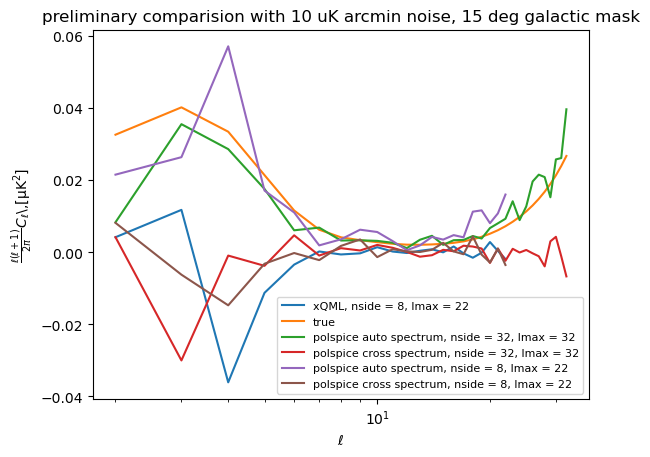

In [46]:
Z_xqml = ell_xqml*(ell_xqml+1)/(2*np.pi)
ls = np.arange(2, lmax+1)
plt.semilogx(ell_xqml, Cl_hat[0]*Z_xqml, label='xQML, nside = 8, lmax = 22')
plt.semilogx(ls, true_spectra[1][ls]*Z, label='true')
plt.semilogx(ls, Clhat_auto[ls]*Z, label='polspice auto spectrum, nside = 32, lmax = 32')
plt.semilogx(ls, Clhat_cross[ls]*Z, label='polspice cross spectrum, nside = 32, lmax = 32')
plt.semilogx(ell_xqml, Clhat_auto_lowl[ell_xqml]*Z_xqml, label='polspice auto spectrum, nside = 8, lmax = 22')
plt.semilogx(ell_xqml, Clhat_cross_lowl[ell_xqml]*Z_xqml, label='polspice cross spectrum, nside = 8, lmax = 22')
plt.legend(fontsize=8)
plt.title("preliminary comparision with 10 uK arcmin noise, 15 deg galactic mask")
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell$\,$\mathrm{[\mu K^2]}$')

Text(0, 0.5, '$\\frac{\\ell(\\ell+1)}{2\\pi}C_\\ell$\\,$\\mathrm{[\\mu K^2]}$')

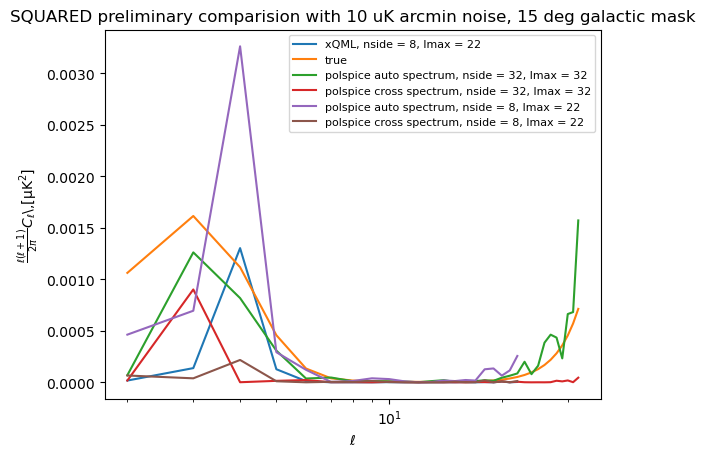

In [47]:
Z_xqml = ell_xqml*(ell_xqml+1)/(2*np.pi)
ls = np.arange(2, lmax+1)
plt.semilogx(ell_xqml, (Cl_hat[0]*Z_xqml)**2, label='xQML, nside = 8, lmax = 22')
plt.semilogx(ls, (true_spectra[1][ls]*Z)**2, label='true')
plt.semilogx(ls, (Clhat_auto[ls]*Z)**2, label='polspice auto spectrum, nside = 32, lmax = 32')
plt.semilogx(ls, (Clhat_cross[ls]*Z)**2, label='polspice cross spectrum, nside = 32, lmax = 32')
plt.semilogx(ell_xqml, (Clhat_auto_lowl[ell_xqml]*Z_xqml)**2, label='polspice auto spectrum, nside = 8, lmax = 22')
plt.semilogx(ell_xqml, (Clhat_cross_lowl[ell_xqml]*Z_xqml)**2, label='polspice cross spectrum, nside = 8, lmax = 22')
plt.legend(fontsize=8)
plt.title("SQUARED preliminary comparision with 10 uK arcmin noise, 15 deg galactic mask")
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell$\,$\mathrm{[\mu K^2]}$')

## Reproducing Results

In [4]:
grid_min = 0
grid_max = 0.15
grid_size = 500

tau_coarse_grid = np.linspace(grid_min, grid_max, 100)

EE_coarse_grid = np.array([
    get_Clhat(t)[1]
    for t in tau_coarse_grid
])

from scipy.interpolate import CubicSpline
EE_cubicspline = CubicSpline(
    tau_coarse_grid, 
    EE_coarse_grid, 
    axis=0
)

tau_grid = np.linspace(grid_min, grid_max, grid_size)

EE_grid = EE_cubicspline(tau_grid)

 Check input parameters an Reionization_xe
 function in the Reionization module


In [31]:
nside = 8
lmax = 22

In [8]:
ell_xqml = np.arange(2, lmax+1)
ell_index_xqml = np.array([np.where(ls == L)[0][0] for L in ell_xqml])
print(ell_index_xqml)
print(ls)
print(ell_xqml)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]
[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]


In [56]:
# xQML setup
bins = xqml.Bins.fromdeltal(2,lmax,1)
ell_xqml = np.arange(2, lmax+1)
ell_bins_xqml = bins.lbin
ell_index_xqml = np.array([np.where(ls == L)[0][0] for L in ell_xqml])
EE_grid_full_xqml = np.zeros((len(tau_grid), lmax + 1))
EE_grid_full_xqml[:, ell_xqml] = EE_grid[:, ell_index_xqml]
EE_grid_binned_xqml = bins.bin_spectra(EE_grid_full_xqml, Dl=True)

EE_input_xqml = np.array(true_spectra[1][:lmax + 1], copy=True)
EE_input_xqml[ell_xqml] = EE_cubicspline(0.054)[ell_index_xqml]
clth_xqml = np.array([
    true_spectra[0][:lmax + 1],
    EE_input_xqml,
    true_spectra[2][:lmax + 1],
    true_spectra[3][:lmax + 1]])

In [46]:
DELTA = 1
bins = xqml.Bins.fromdeltal(2, lmax, DELTA)
ell_b = np.asarray(bins.lbin, dtype=float)      # bin centers
nbins = len(ell_b)

# per-bin inclusive edges, built by hand (Bins.lmin/lmax are global, not per-bin)
lmin_b = 2 + DELTA * np.arange(nbins)
lmax_b = np.minimum(lmin_b + DELTA - 1, lmax)

# number of independent modes per bin: sum_{l in bin} (2l+1)
nu_b = np.array([np.sum(2 * np.arange(l0, l1 + 1) + 1) for l0, l1 in zip(lmin_b, lmax_b)])

ls = np.arange(2, lmax+1)               # ells of EE_grid columns (edit if it starts at 2)
ell_xqml = np.arange(2, lmax + 1)
ell_index_xqml = np.array([np.where(ls == L)[0][0] for L in ell_xqml])

EE_grid_full_xqml = np.zeros((len(tau_grid), lmax + 1))
EE_grid_full_xqml[:, ell_xqml] = EE_grid[:, ell_index_xqml]
EE_grid_binned_xqml = bins.bin_spectra(EE_grid_full_xqml, Dl=True)   # (ntau, nbins)

# fiducial spectra passed to xQML (EE at the fiducial tau)
EE_input_xqml = np.array(true_spectra[1][:lmax + 1], copy=True)
EE_input_xqml[ell_xqml] = EE_cubicspline(0.054)[ell_index_xqml]
clth_xqml = np.array([
    true_spectra[0][:lmax + 1],
    EE_input_xqml,
    true_spectra[2][:lmax + 1],
    true_spectra[3][:lmax + 1],
])

In [9]:
delta = 1
bins = xqml.Bins.fromdeltal(2, lmax, delta)

bins = xqml.Bins.fromdeltal(2, lmax, delta)
ell_b = bins.lbin                 # bin centers, this one works
nbins = len(ell_b)

# per-bin edges, built by hand (inclusive)
lmin_b = 2 + delta * np.arange(nbins)
lmax_b = lmin_b + delta - 1

print(lmin_b[:3], lmax_b[:3], lmax_b[-1], nbins)
print(ell_b[:3])  

[2 3 4] [2 3 4] 22 21
[2. 3. 4.]


In [10]:
# theory binned the same way (for comparing to the estimate)
clEE_theory_b = np.array([true_spectra[1][l0:l1+1].mean() for l0, l1 in zip(lmin_b, lmax_b)])

# map each multipole to its bin index (handy for plotting or unbinning)
ell_xqml = np.arange(2, lmax_b[-1] + 1)
bin_index = (ell_xqml - 2) // delta

In [46]:
print(EE_grid_full_xqml.shape)

(500, 23)


In [52]:
def full_sky_wishart(noise, nsim):
    taus = []
    
    # NOISE CALCS
    npix = hp.nside2npix(nside)
    solid_angle = hp.nside2pixarea(nside)
    # map sensitivity
    sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)
    Nl = 4*np.pi * sigma_pix**2 / npix

    # masking
    temp_mask = np.ones(npix, dtype=bool)

    NoiseVar = (sigma_pix**2 * np.eye(2*npix))

    spec = ['EE','BB']

    esti = xqml.xQML(
        temp_mask,
        temp_mask,
        bins,
        clth_xqml,
        NA=NoiseVar,
        NB=NoiseVar,
        lmax=lmax,
        fwhm=0,
        spec=spec,
        pixwin=False
    )

    var_grid_cross = np.array([
        (1/(2*ell_bins_xqml + 1)) *
        (ee**2 + (ee + Nl)**2)
        for ee in EE_grid_binned_xqml
    ])

    log_var_cross = np.log(2*np.pi*var_grid_cross)

    for i in range(nsim):
        s1 = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pol=True)

        n1 = np.random.randn(npix) * sigma_pix
        n2 = np.random.randn(npix) * sigma_pix 

        map1 = s1[1:3] + n1
        map2 = s1[1:3] + n2

        Clhat_cross = esti.get_spectra(map1, map2)[0]

        # x = ((Clhat_cross[None, :])/(EE_grid_binned_xqml))
        # x = np.maximum(x, 1e-10)
        # chi2_cross = np.sum(
        #     (2*ell_bins_xqml+1)*(x - np.log(x) - 1),
        #     axis=1
        # )

        #Gaussian distribution
        chi2_cross = np.sum(
            ((Clhat_cross[None, :] - EE_grid_binned_xqml)**2 / var_grid_cross) + log_var_cross,
            axis=1
        )

        taus.append(tau_grid[np.argmin(chi2_cross)])
    return np.array(taus)



In [39]:
import warnings

# ---------------------------------------------------------------------------
# Assumed to be defined elsewhere in your script:
#   nside, lmax
#   tau_grid                : (ntau,)
#   EE_grid                 : (ntau, nl_grid) EE Cl for each tau; columns follow `ls`
#   true_spectra            : healpy order [TT, EE, BB, TE], Cl, index = ell from 0
#   EE_cubicspline          : callable, tau -> EE Cl on the `ls` grid
# ---------------------------------------------------------------------------

from scipy.interpolate import interp1d
from scipy.optimize import minimize_scalar

f = interp1d(tau_grid, EE_grid_binned_xqml, axis=0, kind='cubic')

def fit_tau(d, Nl):
    def m2ll(t):
        m = f(t)
        var = (m**2 + (m + Nl * fac_b)**2) / nu_b
        return np.sum((d - m)**2 / var + np.log(2 * np.pi * var))
    return minimize_scalar(m2ll, bounds=(tau_grid.min(), tau_grid.max()), method='bounded').x

# ------------------------------- 1. BINNING --------------------------------
DELTA = 1        # bin width (use 1 for testing, larger for real data)
DL = True       # False: everything in Cl.  True: everything in Dl = l(l+1)Cl/2pi.
                 # Must match what esti.get_spectra returns (see validation below).

bins = xqml.Bins.fromdeltal(2, lmax, DELTA)
ell_b = np.asarray(bins.lbin, dtype=float)      # bin centers
nbins = len(ell_b)

# per-bin inclusive edges, built by hand (Bins.lmin/lmax are global, not per-bin)
lmin_b = 2 + DELTA * np.arange(nbins)
lmax_b = np.minimum(lmin_b + DELTA - 1, lmax)

if not np.allclose(ell_b, 0.5 * (lmin_b + lmax_b)):
    warnings.warn("bins.lbin != (lmin_b+lmax_b)/2: check the bin-edge convention "
                  "(offset by 0.5, or last bin clipped?). Variance below depends on it.")

# number of independent modes per bin: sum_{l in bin} (2l+1)
nu_b = np.array([np.sum(2 * np.arange(l0, l1 + 1) + 1) for l0, l1 in zip(lmin_b, lmax_b)])

# Dl conversion factor at bin centers (1 if working in Cl)
fac_b = ell_b * (ell_b + 1) / (2 * np.pi) if DL else np.ones(nbins)

# ------------------------ 2. THEORY GRID (binned) --------------------------
ls = np.arange(2, 2+ EE_grid.shape[1])                 # ells of EE_grid columns (edit if it starts at 2)
ell_xqml = np.arange(2, lmax + 1)
ell_index_xqml = np.array([np.where(ls == L)[0][0] for L in ell_xqml])

EE_grid_full_xqml = np.zeros((len(tau_grid), lmax + 1))
EE_grid_full_xqml[:, ell_xqml] = EE_grid[:, ell_index_xqml]
EE_grid_binned_xqml = bins.bin_spectra(EE_grid_full_xqml, Dl=DL)   # (ntau, nbins)

# fiducial spectra passed to xQML (EE at the fiducial tau)
EE_input_xqml = np.array(true_spectra[1][:lmax + 1], copy=True)
EE_input_xqml[ell_xqml] = EE_cubicspline(0.054)[ell_index_xqml]
clth_xqml = np.array([
    true_spectra[0][:lmax + 1],
    EE_input_xqml,
    true_spectra[2][:lmax + 1],
    true_spectra[3][:lmax + 1],
])

# ---------------------------- 3. ESTIMATOR ---------------------------------
def build_estimator(noise):
    """noise in uK-arcmin per pixel (Q and U each). Returns (esti, sigma_pix, Nl)."""
    npix = hp.nside2npix(nside)
    solid_angle = hp.nside2pixarea(nside)
    sigma_pix = noise * (np.pi / 180 / 60) / np.sqrt(solid_angle)
    Nl = 4 * np.pi * sigma_pix**2 / npix          # = sigma_pix^2 * solid_angle

    mask = np.ones(npix, dtype=bool)
    NoiseVar = sigma_pix**2 * np.eye(2 * npix)

    esti = xqml.xQML(
        mask, mask, bins, clth_xqml,
        NA=NoiseVar, NB=NoiseVar,
        lmax=lmax, fwhm=0, spec=['EE', 'BB'],
    )
    return esti, sigma_pix, Nl

# ---------------------------- 4. LIKELIHOOD --------------------------------
def gaussian_cross_variance(Nl):
    """Per-tau, per-bin variance of the EE cross-spectrum (full sky, fsky=1).
    Var = (C^2 + (C+N)^2) / nu_b, with C, N in the same convention as the data."""
    Nl_b = Nl * fac_b
    return (EE_grid_binned_xqml**2 + (EE_grid_binned_xqml + Nl_b)**2) / nu_b[None, :]

def neg2_loglike(Clhat, var_grid):
    """-2 ln L (up to a constant) for every tau in tau_grid. Clhat: (nbins,)."""
    return np.sum((Clhat[None, :] - EE_grid_binned_xqml)**2 / var_grid
                  + np.log(2 * np.pi * var_grid), axis=1)

# ---------------------------- 5. SIMULATIONS -------------------------------
def full_sky_wishart(noise, nsim, seed=None):
    rng = np.random.default_rng(seed)
    npix = hp.nside2npix(nside)

    esti, sigma_pix, Nl = build_estimator(noise)      # built ONCE
    var_grid = gaussian_cross_variance(Nl)

    taus = []
    for _ in range(nsim):
        s1 = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pol=True)

        n1 = rng.standard_normal((2, npix)) * sigma_pix   # independent Q,U noise
        n2 = rng.standard_normal((2, npix)) * sigma_pix

        map1 = s1[1:3] + n1
        map2 = s1[1:3] + n2

        # If xqml complains about shape, try map1.ravel(), map2.ravel()
        Clhat_cross = esti.get_spectra(map1, map2)[0]     # index 0 = EE

        result = minimize_scalar(neg2_loglike(Clhat_cross, var_grid), bounds=(tau_grid.min(), tau_grid.max()), method='bounded')
        taus.append(result.x)
        #taus.append(tau_grid[np.argmin(neg2_loglike(Clhat_cross, var_grid))])


    return np.array(taus)

# ---------------------------- 6. VALIDATION --------------------------------
def validate(noise, nsim=50, seed=0):
    """Mean of the estimator over sims should match the binned theory at the true tau,
    and the scatter should match sqrt(var). If the mean is off by l(l+1)/2pi -> flip DL."""
    rng = np.random.default_rng(seed)
    npix = hp.nside2npix(nside)
    esti, sigma_pix, Nl = build_estimator(noise)
    itrue = np.argmin(np.abs(tau_grid - 0.054))
    var = gaussian_cross_variance(Nl)[itrue]

    est = []
    for _ in range(nsim):
        s = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pol=True)
        m1 = s[1:3] + rng.standard_normal((2, npix)) * sigma_pix
        m2 = s[1:3] + rng.standard_normal((2, npix)) * sigma_pix
        est.append(esti.get_spectra(m1, m2)[0])
    est = np.array(est)

    print("mean/theory (should be ~1):", np.round(est.mean(0) / EE_grid_binned_xqml[itrue], 2)[:8])
    print("std/sqrt(var) (should be ~1):", np.round(est.std(0) / np.sqrt(var), 2)[:8])

# taus = full_sky_wishart(noise=..., nsim=...)
# validate(noise=...)

In [53]:
taus = full_sky_wishart(noise=10, nsim=100)

xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.74 Gb 2 spec 21 bin 2 768 pix
Construct Pl: 0.4 sec
Construct S: 0.1 sec
Construct El (nl=42): 6.8 sec
Construct Wll (nl=42): 0.9 sec
Construct estimator: 8.3 sec


In [35]:
validate(10)

xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.74 Gb 2 spec 21 bin 2 768 pix
Construct Pl: 0.4 sec
Construct S: 0.1 sec
Construct El (nl=42): 7.0 sec
Construct Wll (nl=42): 0.7 sec
Construct estimator: 8.4 sec


/tmp/ipykernel_316778/2763834415.py:126: RuntimeWarning: divide by zero encountered in divide
  print("mean/theory (should be ~1):", np.round(est.mean(0) / EE_grid_binned_xqml[itrue], 2)[:8])


mean/theory (should be ~1): [ inf  inf 1.19 1.13 1.12 1.63 2.69 5.32]
std/sqrt(var) (should be ~1): [5066.04 4105.44    1.02    1.39    0.81    1.6     2.15    5.43]


In [15]:
def diagnose(noise, nsim=50, seed=0):
    rng = np.random.default_rng(seed)
    npix = hp.nside2npix(nside)
    esti, sigma_pix, Nl = build_estimator(noise)
    itrue = np.argmin(np.abs(tau_grid - 0.054))

    est = []
    for _ in range(nsim):
        s = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pol=True)
        m1 = s[1:3] + rng.standard_normal((2, npix)) * sigma_pix
        m2 = s[1:3] + rng.standard_normal((2, npix)) * sigma_pix
        est.append(esti.get_spectra(m1, m2)[0])
    est = np.array(est).mean(0)

    th_Cl = bins.bin_spectra(EE_grid_full_xqml[itrue:itrue+1], Dl=False)[0]
    th_Dl = bins.bin_spectra(EE_grid_full_xqml[itrue:itrue+1], Dl=True)[0]
    print("ell_b            :", ell_b[:8])
    print("est/theory (Cl)  :", np.round(est[:8] / th_Cl[:8], 2))
    print("est/theory (Dl)  :", np.round(est[:8] / th_Dl[:8], 2))

diagnose(10)

xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.74 Gb 2 spec 21 bin 2 768 pix
Construct Pl: 0.4 sec
Construct S: 0.1 sec
Construct El (nl=42): 6.7 sec
Construct Wll (nl=42): 0.8 sec
Construct estimator: 8.3 sec
ell_b            : [2. 3. 4. 5. 6. 7. 8. 9.]
est/theory (Cl)  : [ 0.95  1.92  3.13  5.34  6.76  9.83 12.56 15.24]
est/theory (Dl)  : [0.99 1.01 0.98 1.12 1.01 1.1  1.1  1.06]


(array([ 38.68,  38.68,  38.68,  38.68,  38.68,  77.36,  77.36,   0.  ,  38.68, 116.05, 232.09,   0.  ,  77.36,  77.36,   0.  ,  77.36, 154.73,
        154.73,  77.36, 116.05, 116.05,   0.  , 232.09, 154.73, 386.82, 116.05, 154.73, 232.09,   0.  , 309.46,  38.68,   0.  ,  77.36, 193.41,
        116.05,   0.  ,   0.  ,  38.68,  77.36,   0.  ,   0.  ,  38.68,   0.  ,  38.68,   0.  ,   0.  ,  38.68,   0.  ,   0.  ,  38.68]),
 array([0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04,
        0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04,
        0.04, 0.04, 0.05, 0.05, 0.05]),
 <BarContainer object of 50 artists>)

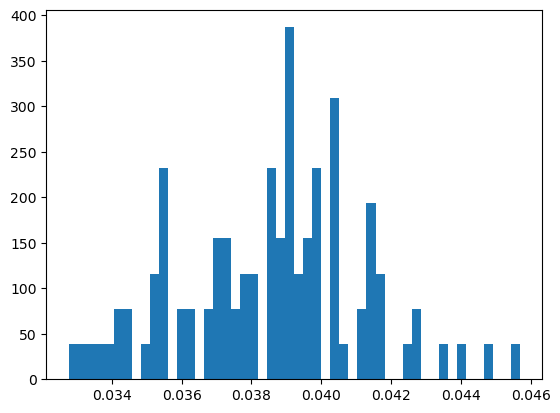

In [54]:
plt.hist(taus, bins=50, density=True)

In [55]:
print(taus.std())

0.002624265713501225


In [27]:
nside = 16
lmax = 30

In [28]:
# Run after xqml_tau_likelihood.py (uses its bins, EE_grid_binned_xqml, etc.), with DL = True.
import numpy as np
import healpy as hp
DELTA = 5

def noise_Nl(noise):
    npix = hp.nside2npix(nside)
    sigma_pix = noise * (np.pi / 180 / 60) / np.sqrt(hp.nside2pixarea(nside))
    return 4 * np.pi * sigma_pix**2 / npix


# ---- Test 1: Fisher floor. Best sigma_tau this likelihood can give for THIS lmax/bins ----
def fisher_sigma_tau(noise, tau0=0.054, ell_cut=2):
    i = np.argmin(np.abs(tau_grid - tau0))
    var = gaussian_cross_variance(noise_Nl(noise))
    dm = np.gradient(EE_grid_binned_xqml, tau_grid, axis=0)[i]
    dv = np.gradient(var, tau_grid, axis=0)[i]
    sel = ell_b >= ell_cut
    F = np.sum((dm**2 / var[i] + 0.5 * (dv / var[i])**2)[sel])
    return 1 / np.sqrt(F)


# ---- Test 2: bypass xQML and pixels entirely (harmonic-space cross spectrum) ----
def harmonic_taus(noise, nsim, seed=0, ell_cut=2):
    np.random.seed(seed)
    Nl = noise_Nl(noise)
    var_grid = gaussian_cross_variance(Nl)
    sel = ell_b >= ell_cut
    taus = []
    for _ in range(nsim):
        E = hp.synalm(true_spectra, lmax=lmax, new=True)[1]        # signal E alm
        E1 = E + hp.synalm(np.full(lmax + 1, Nl), lmax=lmax)       # + independent noise
        E2 = E + hp.synalm(np.full(lmax + 1, Nl), lmax=lmax)
        cl = hp.alm2cl(E1, E2, lmax=lmax)
        cl[:2] = 0
        d = bins.bin_spectra(cl[None, :], Dl=DL)[0]
        l2 = np.sum(((d[None, :] - EE_grid_binned_xqml)**2 / var_grid
                     + np.log(2 * np.pi * var_grid))[:, sel], axis=1)
        taus.append(tau_grid[np.argmin(l2)])
    return np.array(taus)


# ---- Test 3: is xQML itself at the ideal variance, bin by bin? ----
def xqml_scatter(noise, nsim=200, seed=0):
    rng = np.random.default_rng(seed)
    npix = hp.nside2npix(nside)
    esti, sigma_pix, Nl = build_estimator(noise)
    itrue = np.argmin(np.abs(tau_grid - 0.054))
    var = gaussian_cross_variance(Nl)[itrue]
    est = []
    for _ in range(nsim):
        s = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pol=True)
        m1 = s[1:3] + rng.standard_normal((2, npix)) * sigma_pix
        m2 = s[1:3] + rng.standard_normal((2, npix)) * sigma_pix
        est.append(esti.get_spectra(m1, m2)[0])
    est = np.array(est)
    np.set_printoptions(precision=2, suppress=True, linewidth=150)
    print("ell_b            :", ell_b)
    print("std/sqrt(var)    :", est.std(0) / np.sqrt(var))          # ~1 if xQML is ideal
    print("mean/theory      :", est.mean(0) / EE_grid_binned_xqml[itrue])
    return est


#usage:
print("Fisher floor  :", fisher_sigma_tau(10))
t = harmonic_taus(10, 500);  print("harmonic std  :", t.std(), "+/-", t.std() / np.sqrt(2 * len(t)))
est = xqml_scatter(10)

Fisher floor  : 0.0026716955304741147
harmonic std  : 0.00268732525408012 +/- 8.498068616583878e-05
xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 11.81 Gb 2 spec 21 bin 2 3072 pix
Construct Pl: 6.0 sec
Construct S: 1.0 sec


KeyboardInterrupt: 

In [8]:
def full_sky_wishart_test(noise, nsim):
    cls = []
    
    # NOISE CALCS
    npix = hp.nside2npix(nside)
    solid_angle = hp.nside2pixarea(nside)
    # map sensitivity
    sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)
    
    Nl = 4*np.pi * sigma_pix**2 / npix

    bins = xqml.Bins.fromdeltal(2,lmax,1)
    ell_xqml = np.arange(2, lmax+1)
    ell_bins_xqml = bins.lbin
    temp_mask = np.ones(npix, dtype=bool)

    NoiseVar = (sigma_pix**2 * np.eye(2*npix))

    spec = ['EE','BB']

    esti = xqml.xQML(
        temp_mask,
        temp_mask,
        bins,
        true_spectra,
        NA=NoiseVar,
        NB=NoiseVar,
        lmax=lmax,
        fwhm=0,
        spec=spec,
    )

    for i in range(nsim):
        s1 = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pol=True)

        n1 = np.random.randn(npix) * sigma_pix / np.sqrt(2)
        n2 = np.random.randn(npix) * sigma_pix / np.sqrt(2)

        map1 = s1 + n1
        map2 = s1 + n2

        Clhat_cross = esti.get_spectra(map1[1:3], map2[1:3])[0]

        cls.append(Clhat_cross)
    return np.array(cls)

In [32]:
cls = full_sky_wishart_test(noise=0.1, nsim=10)

xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.74 Gb 2 spec 21 bin 2 768 pix
Construct Pl: 0.5 sec
Construct S: 0.1 sec
Construct El (nl=42): 8.5 sec
Construct Wll (nl=42): 0.9 sec
Construct estimator: 11.5 sec


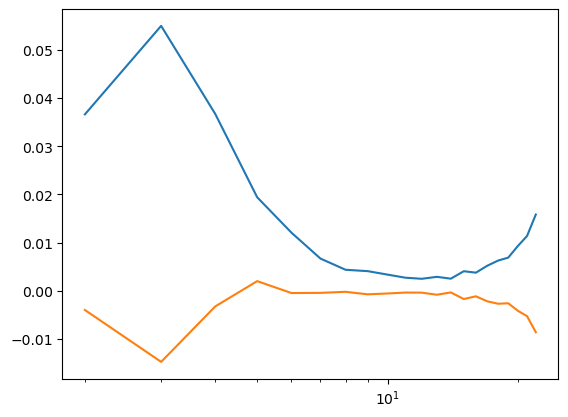

In [33]:
ell_xqml = np.arange(2, lmax+1)
avg_cls = np.mean(cls, axis=0)
plt.semilogx(ell_xqml, avg_cls[ell_xqml==ls]*Z, label='avg cl')
plt.semilogx(ell_xqml, (true_spectra[1][ell_xqml]-avg_cls[ell_xqml==ls])*Z, label='residual')

In [66]:
def cut_sky_masking_test(noise, nsim):
    cls = []
    
    # NOISE CALCS
    npix = hp.nside2npix(nside)
    solid_angle = hp.nside2pixarea(nside)
    # map sensitivity
    sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)
    
    Nl = 4*np.pi * sigma_pix**2 / npix

    theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
    b = np.pi/2 - theta
    gal_deg = 15
    mask_gal = np.abs(b) > np.deg2rad(gal_deg)

    bins = xqml.Bins.fromdeltal(2,lmax,1)
    ell_xqml = np.arange(2, lmax+1)
    ell_bins_xqml = bins.lbin
    #temp_mask = np.ones(npix, dtype=bool)

    npix_masked = np.sum(mask_gal)

    NoiseVar = (sigma_pix**2 * np.eye(2*npix_masked))

    spec = ['EE','BB']

    esti = xqml.xQML(
        mask_gal,
        mask_gal,
        bins,
        true_spectra,
        NA=NoiseVar,
        NB=NoiseVar,
        lmax=lmax,
        fwhm=0,
        spec=spec,
    )

    for i in range(nsim):
        s1 = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pol=True)

        n1 = np.random.randn(npix) * sigma_pix 
        n2 = np.random.randn(npix) * sigma_pix

        map1 = s1 + n1
        map2 = s1 + n2

        Clhat_cross = esti.get_spectra(map1[1:3, mask_gal], map2[1:3, mask_gal])[0]

        cls.append(Clhat_cross)
    return np.array(cls)

In [10]:
def test_xqml(noises, nsim, sim_func):
    spectra_avg = []
    spectra_var = []
    for n in noises:
        spectra = sim_func(n, nsim)
        spectra_avg.append(np.mean(spectra, axis=0))
        spectra_var.append(np.var(spectra, axis=0))
        print(n)

    return np.array(spectra_avg), np.array(spectra_var)

In [11]:
noises = np.arange(0,210,10, dtype=float)
noises = np.insert(noises, 0, 0.1) # add a small noise value to avoid zero noise
spectra_list = test_xqml(noises, 50, full_sky_wishart_test)

xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.74 Gb 2 spec 21 bin 2 768 pix
Construct Pl: 0.4 sec
Construct S: 0.2 sec
Construct El (nl=42): 7.3 sec
Construct Wll (nl=42): 0.9 sec
Construct estimator: 8.9 sec
0.1
xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.74 Gb 2 spec 21 bin 2 768 pix
Construct Pl: 0.5 sec
Construct S: 0.1 sec
Construct El (nl=42): 7.2 sec
Construct Wll (nl=42): 0.9 sec
Construct estimator: 8.8 sec
0.0
xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.74 Gb 2 spec 21 bin 2 768 pix
Construct Pl: 0.5 sec
Construct S: 0.1 sec
Construct El (nl=42): 6.7 sec
Construct Wll (nl=42): 0.8 sec
Construct estimator: 8.2 sec
10.0
xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.74 Gb 2 spec 21 bin 2 768 pix
Construct Pl: 0.5 sec
Construct S: 0.1 sec
Construct El (nl=42): 6.7 sec
Construct Wll (nl=42): 0.9 sec
Construct estimator: 8.3 sec
20.0
xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.74 Gb 2 spec 21 bin 2 768 pix
Construct Pl: 0.5 sec
Construct S: 0.1 sec
Construct El (nl=42): 6.7 sec
Construct Wl

In [68]:
noises = np.arange(0,210,10, dtype=float)
noises = np.insert(noises, 0, 0.1) # add a small noise value to avoid zero noise
spectra_list = test_xqml(noises, 50, cut_sky_masking_test)
# fksy = 0.74

xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.37 Gb 2 spec 21 bin 2 544 pix
Construct Pl: 0.4 sec
Construct S: 0.0 sec
Construct El (nl=42): 4.0 sec
Construct Wll (nl=42): 0.5 sec
Construct estimator: 10.6 sec
0.1
xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.37 Gb 2 spec 21 bin 2 544 pix
Construct Pl: 0.3 sec
Construct S: 0.1 sec


/home/viviantao1/.local/lib/python3.11/site-packages/xqml/xqml_utils.py:21: LinAlgWarning: Ill-conditioned matrix (rcond=4.4103e-21): result may not be accurate.
  inv = linalg.solve(a, I, assume_a='sym', overwrite_b=True, )


Construct El (nl=42): 3.9 sec
Construct Wll (nl=42): 0.7 sec
Construct estimator: 11.2 sec
0.0
xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.37 Gb 2 spec 21 bin 2 544 pix
Construct Pl: 0.4 sec
Construct S: 0.0 sec
Construct El (nl=42): 4.1 sec
Construct Wll (nl=42): 0.5 sec
Construct estimator: 9.1 sec
10.0
xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.37 Gb 2 spec 21 bin 2 544 pix
Construct Pl: 0.4 sec
Construct S: 0.0 sec
Construct El (nl=42): 4.4 sec
Construct Wll (nl=42): 0.5 sec
Construct estimator: 9.9 sec
20.0
xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.37 Gb 2 spec 21 bin 2 544 pix
Construct Pl: 0.3 sec
Construct S: 0.0 sec
Construct El (nl=42): 4.0 sec
Construct Wll (nl=42): 0.5 sec
Construct estimator: 9.0 sec
30.0
xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.37 Gb 2 spec 21 bin 2 544 pix
Construct Pl: 0.3 sec
Construct S: 0.0 sec
Construct El (nl=42): 4.3 sec
Construct Wll (nl=42): 0.6 sec
Construct estimator: 9.4 sec
40.0
xQML
spec: ['EE', 'BB']
nbin: 21
Memset: 0.37 Gb 2 spec 21 bi

In [23]:
print(len(spectra_list[0]))
print(ls)
print(ell_xqml)

22
[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]
[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]


In [32]:
for i in spectra_list[0]:
    print(i)

[2.90944707e-02 2.18625908e-02 1.13744348e-02 4.12995552e-03
 1.63169083e-03 7.06229877e-04 4.02328585e-04 2.65496002e-04
 1.75010237e-04 1.24604950e-04 1.06917423e-04 9.30523645e-05
 9.04619513e-05 8.91699271e-05 9.42013351e-05 9.29594108e-05
 1.12170787e-04 1.27164325e-04 1.43322064e-04 1.59929659e-04
 1.96186058e-04]
[ 0.12847278  0.06973835  0.0365255  -0.02403759  0.04898101  0.13499311
 -0.22272414 -0.0053133   0.06318105 -0.08998546 -0.30106354  0.11090786
 -0.11322857  0.03211107 -0.3437405  -0.21860067  0.02627855 -0.01764486
  0.08616002 -0.21234677 -0.18999024]
[3.40424547e-02 2.28294482e-02 1.06398927e-02 5.06085672e-03
 1.78331341e-03 7.43905211e-04 3.83154209e-04 2.54984949e-04
 1.83258486e-04 1.42287898e-04 1.07789814e-04 9.61113078e-05
 8.46340249e-05 9.07381993e-05 9.02375026e-05 1.05337607e-04
 1.12741648e-04 1.25874147e-04 1.47185671e-04 1.78339336e-04
 1.87710179e-04]
[3.57966786e-02 1.99375475e-02 1.05222711e-02 4.70935781e-03
 1.86561593e-03 7.36035053e-04 4.28588

Text(0.5, 1.0, 'avg xQML estimated EE spectra with 15 deg galactic mask, 50 simulations per noise level')

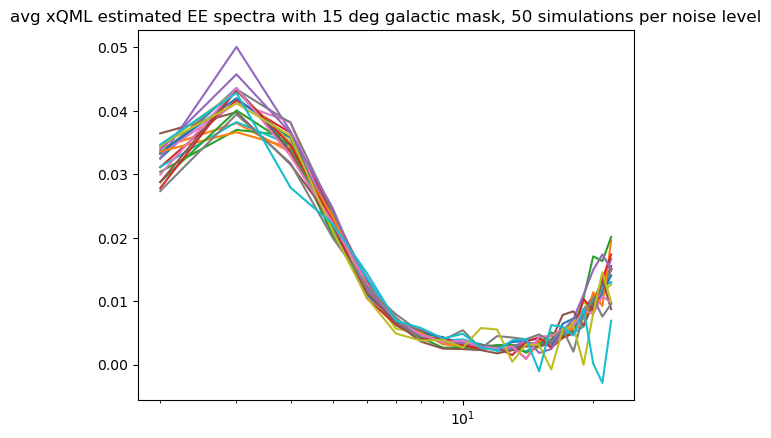

In [35]:
ell_xqml = np.arange(2, lmax+1)
for cl in spectra_list[0][2:]:
    plt.semilogx(ell_xqml, cl[ell_xqml==ls]*Z)
plt.title("avg xQML estimated EE spectra with 15 deg galactic mask, 50 simulations per noise level")

Text(0.5, 1.0, 'variance xQML estimated EE spectra with 15 deg galactic mask, 50 simulations per noise level')

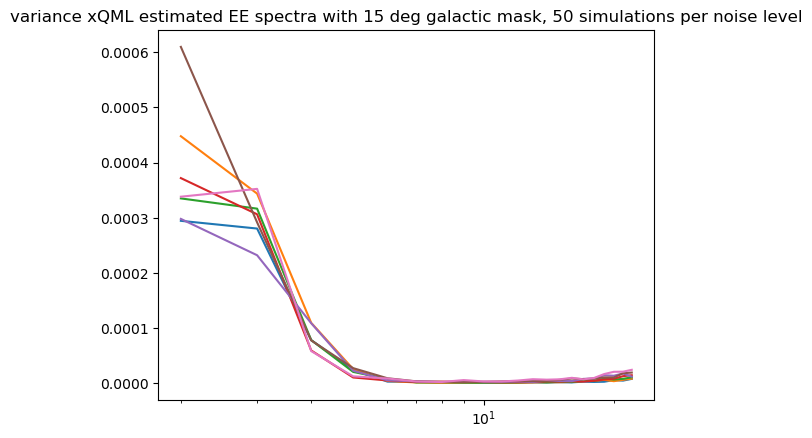

In [55]:
ell_xqml = np.arange(2, lmax+1)
for cl in spectra_list[1][15:]:
    plt.semilogx(ell_xqml, cl[ell_xqml==ls]*Z)
plt.title("variance xQML estimated EE spectra with 15 deg galactic mask, 50 simulations per noise level")

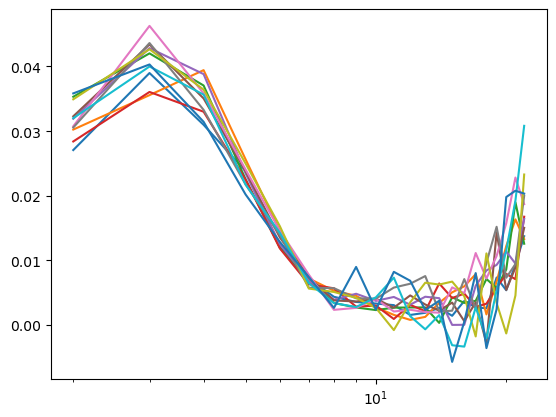

In [29]:
for cl in spectra_list[10:]:
    plt.semilogx(ell_xqml, cl[ell_xqml==ls]*Z)

In [9]:
def sigma_tau_plot(noises, nsim, sim_func):
    sigma_tau = []
    bias_tau = []

    for n in noises:
        auto = sim_func(n, nsim)
        sigma_tau.append(auto.std())
        bias_tau.append(auto.mean() - 0.054)
        print(n)

    return np.array(sigma_tau), np.array(bias_tau)

In [56]:
def tau_study(noises, nsim, sim_func):
    taus = []

    for n in noises:
        auto = sim_func(n, nsim)
        taus.append(auto)
        print(n)

    return np.array(taus)

In [10]:
noises = np.arange(10,210,10, dtype=float)
noises = np.insert(noises, 0, 0.1)
sigma, bias = sigma_tau_plot(noises, 500, full_sky_wishart)

xQML
spec: ['EE', 'BB']
nbin: 5
Memset: 0.18 Gb 2 spec 5 bin 2 768 pix
Construct Pl: 0.1 sec
Construct S: 0.0 sec
Construct El (nl=10): 2.3 sec
Construct Wll (nl=10): 0.2 sec
Construct estimator: 3.3 sec
0.1
xQML
spec: ['EE', 'BB']
nbin: 5
Memset: 0.18 Gb 2 spec 5 bin 2 768 pix
Construct Pl: 0.1 sec
Construct S: 0.0 sec
Construct El (nl=10): 2.0 sec
Construct Wll (nl=10): 0.2 sec
Construct estimator: 3.0 sec
10.0
xQML
spec: ['EE', 'BB']
nbin: 5
Memset: 0.18 Gb 2 spec 5 bin 2 768 pix
Construct Pl: 0.1 sec
Construct S: 0.0 sec
Construct El (nl=10): 2.0 sec
Construct Wll (nl=10): 0.2 sec
Construct estimator: 2.8 sec
20.0
xQML
spec: ['EE', 'BB']
nbin: 5
Memset: 0.18 Gb 2 spec 5 bin 2 768 pix
Construct Pl: 0.1 sec
Construct S: 0.0 sec
Construct El (nl=10): 2.0 sec
Construct Wll (nl=10): 0.2 sec
Construct estimator: 2.9 sec
30.0
xQML
spec: ['EE', 'BB']
nbin: 5
Memset: 0.18 Gb 2 spec 5 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=10): 1.9 sec
Construct Wll (nl=10)

In [11]:
import pandas as pd
goal = pd.read_csv("goal_table.csv", names=['noise','sigma_tau'])

In [50]:
noises = np.arange(10,210,10, dtype=float)
noises = np.insert(noises, 0, 0.1)
print(noises[18:])

[180. 190. 200.]


In [49]:
print(len(noises), len(sigma), len(bias))

21 21 21


(5, 210)

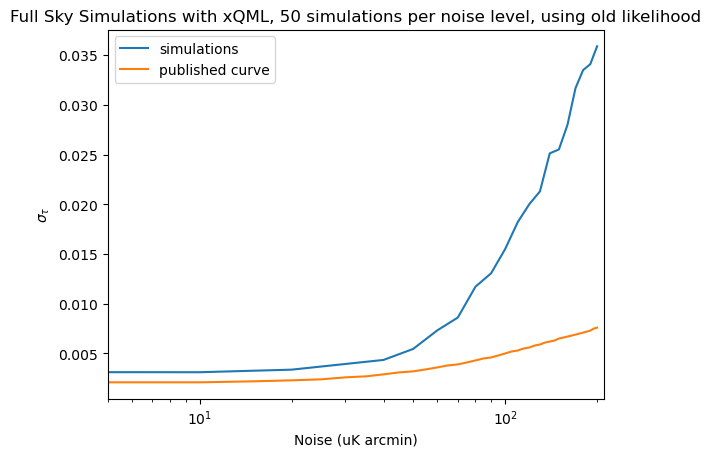

In [14]:
plt.semilogx(noises, sigma, label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Full Sky Simulations with xQML, 50 simulations per noise level, using old likelihood")
plt.legend()
plt.xlim(5,210)

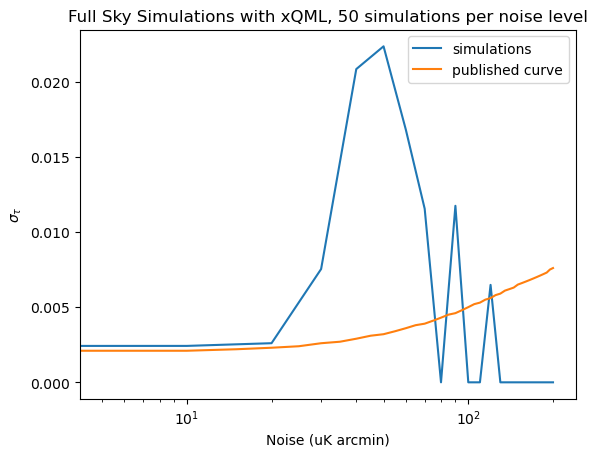

In [49]:
plt.semilogx(noises, sigma, label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Full Sky Simulations with xQML, 50 simulations per noise level")
plt.legend()

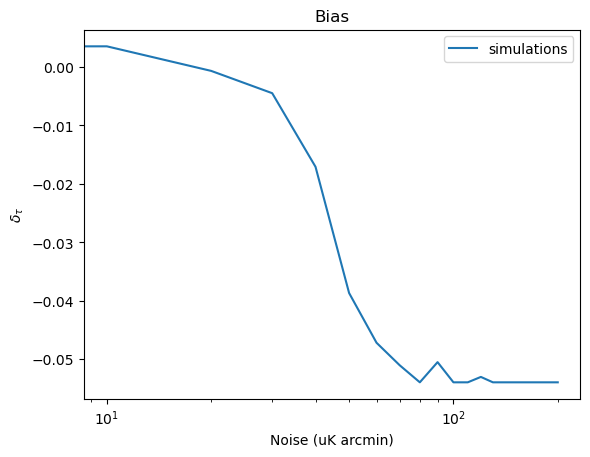

In [55]:
plt.semilogx(noises, bias, label='simulations')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\delta_{\tau}$')
plt.title("Bias")
plt.legend()